In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter, CoxPHFitter

df = pd.read_csv("../data/processed/telco_clean.csv")
df = df[df["tenure_months"] > 0]   # drop the 11 never-billed customers
print(df.shape)

(7032, 33)


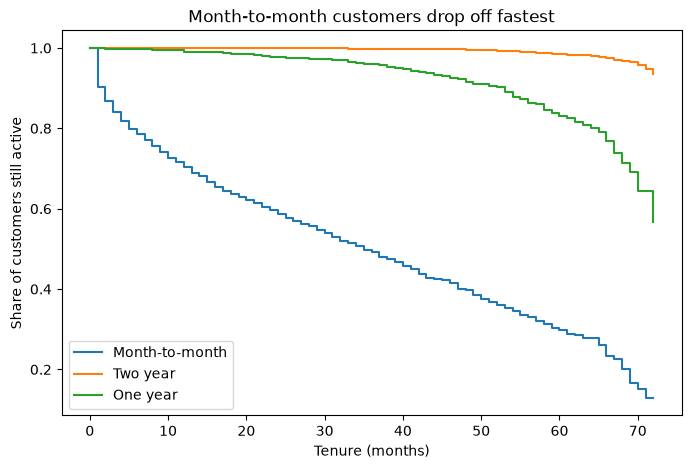

In [2]:
kmf = KaplanMeierFitter()
fig, ax = plt.subplots(figsize=(8, 5))
for c in df["contract"].unique():
    m = df["contract"] == c
    kmf.fit(df.loc[m, "tenure_months"], df.loc[m, "churn_value"], label=c)
    kmf.plot_survival_function(ax=ax, ci_show=False)
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Share of customers still active")
ax.set_title("Month-to-month customers drop off fastest")
plt.savefig("../reports/figures/km_by_contract.png", bbox_inches="tight", dpi=150)
plt.show()

Concordance: 0.862


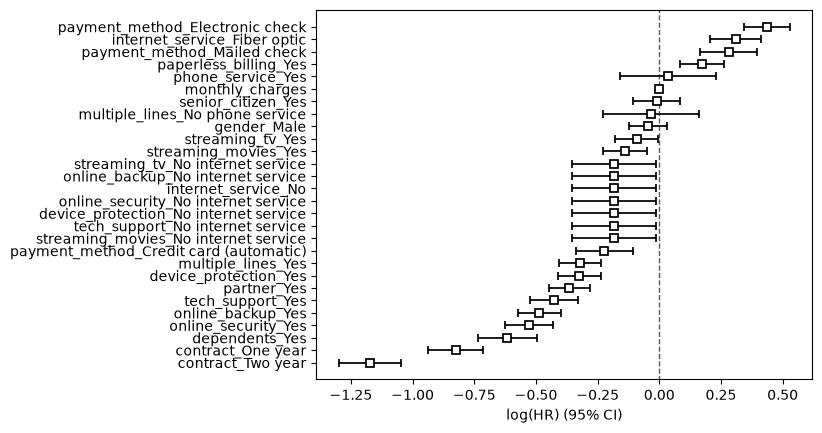

In [3]:
# total_charges dropped: it is roughly tenure x monthly charges, which confuses the model
drop_cols = ["customerid", "count", "country", "state", "city", "zip_code",
             "lat_long", "latitude", "longitude", "churn_label", "churn_score",
             "churn_reason", "cltv", "total_charges"]

cox_df = pd.get_dummies(df.drop(columns=drop_cols), drop_first=True).astype(float)

cph = CoxPHFitter(penalizer=0.1)
cph.fit(cox_df, duration_col="tenure_months", event_col="churn_value")
print("Concordance:", round(cph.concordance_index_, 3))
cph.plot()
plt.savefig("../reports/figures/cox_hazard_ratios.png", bbox_inches="tight", dpi=150)
plt.show()

In [4]:
# hazard ratio > 1 speeds up churn, < 1 slows it down
cph.summary[["exp(coef)", "p"]].sort_values("exp(coef)", ascending=False)

,exp(coef),p
covariate,,
payment_method_Electronic check,1.547133,9.881282e-21
internet_service_Fiber optic,1.363514,4.862077e-09
payment_method_Mailed check,1.325281,1.602277e-06
paperless_billing_Yes,1.188766,1.169414e-04
phone_service_Yes,1.035320,7.278231e-01
monthly_charges,0.999887,9.204004e-01
senior_citizen_Yes,0.989877,8.342459e-01
multiple_lines_No phone service,0.965885,7.278231e-01
gender_Male,0.954431,2.373726e-01
